# Задача №4. Переливание компота

Нужно сделать так, чтобы во всех пяти стаканах было поровну компота. За одно поднятие можно перелить компот из одного стакана сразу в несколько других.

## Что нужно решить до программирования

- **Сколько компота и какой объём стаканов?** Для опыта возьмём 750 мл и пять стаканов по 300 мл. Считаем объём порциями по 50 мл. В конце в каждом стакане должно быть по 150 мл.
- **Что видит агент?** Объёмы во всех пяти стаканах. Состояние запишем как кортеж из пяти чисел.
- **Что агент может сделать за один ход?** Выбрать стакан с излишком и сколько порций из него перелить. Среда разливает этот объём по стаканам, где компота не хватает, по порядку их номеров. Можно перелить часть излишка и вернуться к этому стакану позже.
- **Когда заканчивается эпизод и какая награда?** Эпизод заканчивается, когда везде по 150 мл. За каждое поднятие даём −1, поэтому чем больше суммарная награда, тем меньше поднятий.
- **Как узнать правильный минимум?** Каждый стакан, в котором изначально больше 150 мл, нужно поднять хотя бы один раз. За это поднятие можно разлить весь его излишек по стаканам, где есть недостача. Поэтому минимум равен числу стаканов с излишком в начале.

## Среда

In [1]:
%matplotlib inline

from collections import defaultdict
from itertools import product
from random import Random

import matplotlib.pyplot as plt

GLASSES = 5
UNIT_ML = 50
CAPACITY = 6
TARGET = 3
TOTAL = GLASSES * TARGET
goal = (TARGET,) * GLASSES

starts = [
    state
    for state in product(range(CAPACITY + 1), repeat=GLASSES)
    if sum(state) == TOTAL and state != goal
]


def actions(state):
    return [
        (source, amount)
        for source, volume in enumerate(state)
        for amount in range(1, volume - TARGET + 1)
    ]


def pour(state, action):
    source, amount = action
    volumes = list(state)
    volumes[source] -= amount

    for destination, volume in enumerate(volumes):
        if volume < TARGET:
            portion = min(amount, TARGET - volume)
            volumes[destination] += portion
            amount -= portion
            if amount == 0:
                break

    return tuple(volumes)


def min_lifts(state):
    return sum(volume > TARGET for volume in state)


print(f"Всего неравномерных начальных состояний — {len(starts)}")

Всего неравномерных начальных состояний — 1450


## Обучение агента

Используем Q-learning. Для каждой пары «состояние, действие» храним оценку будущей суммарной награды. После переливания обновляем её с учётом штрафа за поднятие и лучшей оценки в новом состоянии. Действие всегда даёт один и тот же результат, поэтому берём скорость обучения α = 1. Все поднятия стоят одинаково, поэтому берём коэффициент дисконтирования γ = 1.

В начале эпизода случайно выбираем одно из начальных состояний. Во время обучения с вероятностью ε пробуем случайное действие. Постепенно уменьшаем ε, чтобы агент чаще выбирал то, что уже выучил.

In [2]:
rng = Random(42)
q = defaultdict(float)
alpha = 1.0
episodes = 40_000
checkpoint = 1_000


def best_action(state):
    return max(actions(state), key=lambda action: q[state, action])


def run_agent(state):
    steps = []
    while state != goal:
        action = best_action(state)
        state = pour(state, action)
        steps.append((action, state))
    return steps


def mean_reward():
    return -sum(len(run_agent(state)) for state in starts) / len(starts)


checkpoints = [0]
rewards = [mean_reward()]

for episode in range(1, episodes + 1):
    state = rng.choice(starts)
    epsilon = max(0.05, 1 - episode / (episodes / 2))

    while state != goal:
        if rng.random() < epsilon:
            action = rng.choice(actions(state))
        else:
            action = best_action(state)

        next_state = pour(state, action)
        next_value = max((q[next_state, a] for a in actions(next_state)), default=0)
        reward = -1
        q[state, action] += alpha * (reward + next_value - q[state, action])
        state = next_state

    if episode % checkpoint == 0:
        checkpoints.append(episode)
        rewards.append(mean_reward())

## Кривая обучения

Каждые 1000 эпизодов запускаем агента из всех неравномерных состояний без случайных действий и обновления Q. Для графика усредняем суммарную награду за эти прогоны. Пунктир показывает, какую среднюю награду получил бы агент при минимальном числе поднятий в каждом состоянии.

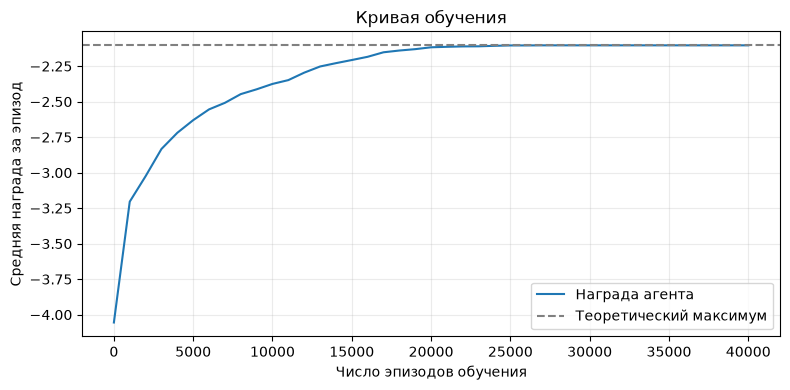

In [3]:
optimal_reward = -sum(min_lifts(state) for state in starts) / len(starts)

plt.figure(figsize=(8, 4))
plt.plot(checkpoints, rewards, label="Награда агента")
plt.axhline(optimal_reward, color="gray", linestyle="--", label="Теоретический максимум")
plt.title("Кривая обучения")
plt.xlabel("Число эпизодов обучения")
plt.ylabel("Средняя награда за эпизод")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## Проверка

In [4]:
examples = [
    (3, 3, 3, 3, 3),
    (6, 3, 2, 2, 2),
    (6, 5, 3, 1, 0),
    (4, 4, 4, 3, 0),
]

for start in examples:
    state = start
    steps = run_agent(start)
    print("Начальные объёмы в мл", [volume * UNIT_ML for volume in start])
    for (source, amount), next_state in steps:
        recipients = [
            f"№{i + 1} (+{(after - before) * UNIT_ML} мл)"
            for i, (before, after) in enumerate(zip(state, next_state))
            if after > before
        ]
        print(
            f"  Из стакана №{source + 1} перелили {amount * UNIT_ML} мл"
            f" → {', '.join(recipients)}"
        )
        state = next_state
    print("Итоговые объёмы в мл", [volume * UNIT_ML for volume in state])
    print(f"Поднятий {len(steps)}, минимум {min_lifts(start)}\n")

optimal_count = sum(len(run_agent(state)) == min_lifts(state) for state in starts)
print(f"Минимум достигнут в {optimal_count} из {len(starts)} начальных состояний.")
print(f"Средняя награда выросла с {rewards[0]:.2f} до {rewards[-1]:.2f}.")

Начальные объёмы в мл [150, 150, 150, 150, 150]
Итоговые объёмы в мл [150, 150, 150, 150, 150]
Поднятий 0, минимум 0

Начальные объёмы в мл [300, 150, 100, 100, 100]
  Из стакана №1 перелили 150 мл → №3 (+50 мл), №4 (+50 мл), №5 (+50 мл)
Итоговые объёмы в мл [150, 150, 150, 150, 150]
Поднятий 1, минимум 1

Начальные объёмы в мл [300, 250, 150, 50, 0]
  Из стакана №1 перелили 150 мл → №4 (+100 мл), №5 (+50 мл)
  Из стакана №2 перелили 100 мл → №5 (+100 мл)
Итоговые объёмы в мл [150, 150, 150, 150, 150]
Поднятий 2, минимум 2

Начальные объёмы в мл [200, 200, 200, 150, 0]
  Из стакана №1 перелили 50 мл → №5 (+50 мл)
  Из стакана №2 перелили 50 мл → №5 (+50 мл)
  Из стакана №3 перелили 50 мл → №5 (+50 мл)
Итоговые объёмы в мл [150, 150, 150, 150, 150]
Поднятий 3, минимум 3

Минимум достигнут в 1450 из 1450 начальных состояний.
Средняя награда выросла с -4.06 до -2.10.


## Выводы

- Средняя награда выросла с −4,06 до −2,10. Чем ближе награда к нулю, тем меньше поднятий.
- После 40 000 эпизодов агент достиг минимума во всех 1450 неравномерных состояниях модели. Например, он за одно поднятие разлил 150 мл из первого стакана по трём другим.